# RutaBio · PSO vs ACO en el problema del agente viajero (TSP) sobre una red vial real
**Proyecto integrador – Algoritmos bioinspirados · Centro de Monterrey, Nuevo León**

Este notebook:
1. Descarga de **OpenStreetMap** las calles reales del **Centro de Monterrey** (radio de 1,100 m alrededor de la Macroplaza) y arma una red vial **dirigida** (respeta calles de un solo sentido y velocidades por tipo de vía).
2. Calcula las matrices de distancia (km) y tiempo (min) con Dijkstra.
3. Obtiene el **óptimo exacto** (Held–Karp) y la heurística del **vecino más cercano** como referencias.
4. Compara **PSO** (random keys), **ACO** (Ant System elitista) y los híbridos **+2-opt** con búsqueda en malla de hiperparámetros (15 corridas por configuración).
5. Genera tablas, gráficas, mapas de las rutas sobre las calles y `resultados.json` (lo usa la página web de demostración).

**Cómo correrlo:** *Entorno de ejecución → Ejecutar todo*. Con internet en Colab se descarga la red desde OpenStreetMap y se dibuja el mapa real de calles. Por defecto el experimento usa una **copia congelada** de esa descarga (`USAR_COPIA = True`) para que los resultados sean siempre los mismos que los del reporte; con `USAR_COPIA = False` se usa la descarga del día.

© colaboradores de OpenStreetMap (ODbL).

In [1]:
# Instalación (solo Colab)
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx"])

In [2]:
# Configuración
import os, time, json, itertools, zlib, base64
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra, connected_components

# ---- Ubicación: Centro de Monterrey, Nuevo León (Macroplaza) ----
LUGAR   = "Centro de Monterrey, Nuevo León, México"
CENTRO  = (25.6694, -100.3099)   # (latitud, longitud) de la Macroplaza
RADIO   = 1100                   # metros alrededor del centro
USAR_COPIA = True                # True: copia congelada de la descarga (resultados reproducibles)

SEMILLA   = 7       # semilla de las paradas
N_PUNTOS  = 15      # 1 depósito + 14 paradas
ITERS     = 200
CORRIDAS  = 15
OUT = "resultados"; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
C_ACO, C_PSO, C_HIB, C_REF = "#7c3aed", "#0d9488", "#ea580c", "#475569"

## 1. Red vial dirigida del Centro de Monterrey (OpenStreetMap)
Nodos = cruces, aristas = tramos de calle con longitud (km) y velocidad (km/h). Si una calle es de un solo sentido la arista existe solo en esa dirección. La velocidad es la registrada en OSM (`maxspeed`) o una velocidad típica estimada por tipo de vía (no es tráfico real). Se conserva la componente fuertemente conexa más grande.

In [3]:
# Copia congelada de la descarga de OpenStreetMap (Centro de Monterrey, 1,100 m alrededor de la Macroplaza)
COPIA_B64 = """
eNq1fcuOJMeR4K8UeC4Q/naPvVGkSIkQJQ4paDESeEhWp5olVFf2ZlU1RlzsYT9FRx50WOi21/6xsZe7W0aGR2R2z1zYlZb+MDe3t5kn//cnj4
dX+6dP/sdf/mI/jWW6tZ86N/1w+xfz6RTirfk0xgyf7KfWRvhO/vYe/i458KcQ4NMkX8V86z41yfMnhwNzTvTJ4bg0yd+0nHP8yTn8lCJ/otXr
HPxmioU/RYerR5mVAnyy0RO63iVAN2fHn7yDT5NJ9MkRiqUwVs7Qd5OsCfMQUyv7WSSBl5ETohISf+fp2Kk4+VQQZ8Pn8TbjpxjkO1xzCnwGny
ziGWQV2r2tYifEmk4O0CkgZkLYKSHWUTDLuEH0vF2kDWKS7ejeYi60SMlI2uSYEIX+5m8iIZliEYJNdBxcHq8Mt060BiDrCePIX3mmM9MrxISf
HA80jm+E0So00hCdYYwt+CkwZ6RAaxqmSQz4HTAVn80T10z83eRoXmYuTJGW5E8hZ0KMiZc8bW54kRBoc8eomERryPoODz5NzCkx45LWWyZD4d
MF+gS8SlgyzoX4chK+8YGwDHxwS18lph5MoAtnySmJDjDx5pMlZshebo4WsXzUYokv5UIyHYBZtrAgGb78RJtZ4QQSxTLxZiExVsIYxM2TEyRJ
kHir4GkNz+ecIgntxDTIiahlmT5AbEKfEZ4M7ZYZrUgyZ3zm9SfcrYgEGuSnyfCSNjKSvJ3nNRhhEv0S+VMkAS+BBSCTnDqeVEgPWEHYIicXw1
w9TSRugmIwJIrCFdHgIpXcOSk9kyZLMsucnAsJh3BdKY7EQXiQxC1loWMmyRcpNX6iq+FTW2OJkvwdyjqyBX9CWUHtxZ9ipBsIfAQTbeN5WMXy
J1FeE6lNoZen8ySmQySNGnmN7Ok8It7Fdp1qkKvwkxUxKllpq0A4J5GOGIkOyQlViA6B6SfKxAsrZ6vUSWCFzhtkQgxuSWwHXaSQ1tB5SmGh8j
StCMPy9Xv+KjJnO56WiKFK1RF0rcWwyqOzTSwPZaJz86VOfGwyM6g3iHaR2dVm5hORsECXIwopTHSYJIKfPKlePo2hQ4uZSbiGqNBIshETf5UJ
3+izKAH8YMWWsio3wpTEr0GMDFhY/CR7JeJ6Xw0Csa8TUc/ETl42z4G/q8JS6Lv6icyYsFPED17oaEjneF+/w839JBrI0gmKcC/xjC9eVC9+5y
uL0r3ZxLyWkAymYkma0YhSQ6xMEq7AnY0oyUQ6TfgFWBg/ZCuMHGhxUU4ZTeQkW3k+deUz8hWsLGnoArKzwp44LwoegT5kkVLQ5Ogd8JJuKmj6
bJDrQLfHWpF8oB18Z9gSWmALPCATOdGatqthlFzewNE0lxSPu2r5CEkrvBszH5wHphLbwZHzLR3OiRmhozqRRLpFax3jxa5aYZwteUJh8mK9Ee
coI/mTkQ/R0VHFAcDTOCOzCh7HTeIOEL3MJMvjQMMIp0YCxB7p6EoQeSWCVLH0tIK4LxPT2FvRKvjJiY6eyAfysmahu/EyrxjE3ldvI9N+VVPh
oW0U0gWkf3VLcqENxClFY2eE11AbEGK5WiNaUjwDG2gR0cm4deU0z+NCaTrBiOyx84fTxDv2RC2xVCbQKpYZL1i6DHFEAq8pQut4c0bL8eZZTA
VhXCaxs4GIzt+ZhDfqTbWmuU5Dn5YPGsQbiLS1fCJGMLI1+nRo10Sc+brFnhqSAFdlhVbxsoMlEXDir6JmQRKJ90cCUV0iT361FV3uaF4Uq+zp
CJPIQKB5U6ieD5KoiCPqEBXxows5s0ZsWCiskMS+0cBJJCeT3jEimmDhaTe5OuLEMDmlmJnQaANJUus8UlhGdk90rWUSWxuRYklwpgPEWA+O2w
W5O7RAqAgrX+LI3EIdGhm8qChSX3LlxM7iD6AzaDiqYsWJsi6WhHb24g5MOG4StT+R6GSRD+OIXDXuy4SHFetErrOTuMCQC8PKBO1qJONRiU5W
Jiht5YQ+E/nRrnqNpLSbTBNdjRO9Q6bRkc8KqoY+iJqI5AfJB946iOsf2VKZJOuTpRJOJ7PlrPgDpFJDUi68a9EKGZ2p+zbo7Yoj4htFDIU1aC
5EGg3doViBYiwxkBzN0acoSpToKmbekil3YoEseZtsocn24FXJNfJh5BZtQT7wEsg4dv+Em9BJRY4Joj+m5tyiWidvZKojcZGqQPAyTHXh2fuw
4sOTrzNV3UIhgxETakjDTmKxLe8mKsNOFERJyMDOsxOlashzD5WWpQeMqKE5aJNPHOslcZDZURQFhbxchOaOQxnR4JY8NyfCB+fC25GY0PIn4W
wXOengxEd1JC0S6lHMFsWUWQrZi7j4E/lkSWSAUxxG1rQkVz0zQms6+cQRtvjElqxQrh6yIemUqNAaSjtIKGKJTevdTcSYRsK4SMq52hPrcXdb
+YF2dyIUltRqEjUOTh25Q5JkKcTsIsd+yjRSpJqYJVc1TqyZWwoEP4EAs74hYzCVihlSyYjtpL+FAzLNyuLPRZKfIvydXLeWGPlY5SaAQ4PzvN
wX6TP2mlGiyYDZIk4VGSkJduBcZBNFX5IqSuKn5cJ+vhKFLMbTUiARhKUNKeAi3xXyt6ozUFw3+GirGs5oGknPVil3pEYkrKOoywoiIXV94EQf
WBG8ROkE66qvTULikvigkaJ6uQGKpSR0sBzsiDEgBZCCuDkU7MRY8yGO9KVEqbRKJRepWVsTJ4GdzupR03F8tSEckkmmhKLumtRKZN7rZuQx1P
CGnMzY0nnoPkj4RPolyB06MnlBEn/Ws6YTMeav5CrIQRSuMCQrXqIuQ9LhRStNRDgfuuuCWkOkkT4k3/xitPfiLpDmEcclRbrdamgCaWrxTjKl
MkINMdgXFs4i9vRFFBt5INWIUkA5VbeC5DLnllszkg1EFRu0xWADJdkcVzhSk0+U9/HVrWQjarzyK5PctZ/Yf++RIV5OTbyR+hBfm1zJJpekS5
y4V4ZkNorGDUTJInlECudrKMWRuXCWhKgibIHNobAjGWlBI1E6Qs6S6Qqr61t8M+bk55DXkqtI9q/ETEpyiyjcLrffCylc/CRag3lT4ljmaDdV
p5TCLRFPzHxQHCGfSKzzJPnXQk6FaBvLieAiDiW5pTW8I360wrmWQ7OaCCZcqu8WyaYV8VRiYjsSZU3iVieeHK1SatbBBMW7haKn6jCTsLXNKR
KMsp0loU+mCumkAgzyIqMEiaTW/SQeH5mNIAMnIkMQb9ASw/hQ5/EduB9+uP1k/+o1lybMLTgTpGOB1l6Cz9vAsawBlMKERimZkiYggeONbl3k
SA/Md4jA7CVOpkBcA6dmlryFDzgC3Nu6rLv1JKwWcV5aFtiM8DcYxMokf8vkA1IJBDiOAx5wwhuI0J1A3gUSbznumnKHBLZ/U4WkW7aIwHKxQh
xHrMvHzvS1xbPLEvmW8AVqLY2Hk1MIYTApuEimwijAXS/Nn+p8UDgVRRA+Q1indnoAyPE1SIjUTotZUKYAUKbDLJMpNIIDIPKwrEAUTlvU+hXm
b12cER2u1VOABr6hU0B2yCyWkdRI0vcW6zJyNMxQ0kijWDHdUqwFTF/aOPhWTge7JQHC5XAon3wjFhZlyG9z7YrRdLNjB0euMCDSRFTFVGsHsv
2wxfTDTLfOcHqibQIA9g4dOvW+AT0lEywa0TrS3nKyx7dhcCmcH8jteADwmcYF2G5ZutwtWWNgnL64r9NcZ2j0oO00u064xOwq+Tosiui164T7
DWY+DmjvmY2c10DCB+jQbg5EXdI104j7YQj7dyV2wsFfnNfB0LAeA+6CHVaMMgXokcc5ndI52iPdb8kYNyJgKMfuu+9qBUSF5obcxzm5M7BjbW
ssTBqmTGpUACATIcfGvR6Zn9GxfSACiVXRHa4jgc9NnIkiAlnYJzhtHQkmzrBsp446aCn2hDFdVUcCp2fDxLjNAgNS8t3ndlUACExI0xaES44C
CwoWGBvfYUB6Xq9MChYEwXbzEBxJUjN0DQ0YlPlcpN1MrQAspPlc4MO55oJBgXm4dFjms8G4dt5QbpOd0QC0bZpmtgBgkc8b2jkAuZRn6yHMz/
QvEK/KU1EwkafULRDQxZiZukXgXPBgOyKCNV2NkmLicX1jNKNMhD4XVy6sMfsmcCZybYCVkwJmJmtoDAdKIggP9yMDk8mRG6hUu5Gcgjl2blxH
ECjt5lSYbrOdsXQylYu6agSYcFs3t0DzyNzRCQOwlGbckRoHdsIALApX9j08c7nF8kaHSUK1cyDQLqeZFgWYrNdvHU4kXNQvCWDCbR0VoLyfMS
UGqRKhd5oC1dLcIUL31bk5AUu9I4UMsH6YcRZgMk3nMLYbypLnxubeapgcuIGA84XLg4JxlQTWa0QF+cjC+UXBrGNg6Sv6Kg7dmUGYyI3yvNAN
TNU6xQYUXugeBIY1hm1saISF2xTGLAokfNlJA3SJYXZkYIAkerrvAaQ2MxsBhy8ES83AwGdGuZRJwbxpfJ4CWKQy+YSeNfjOGHqAp1HkvpsJAd
g0ZwwsLpswUy8ALMJqbS5aNMY2N24GoOfbLaW5FCA8hY/aTTHGliZV9qvAeFvSfDLSXdydRmQYVXgXuJLYYFx3saZTHt19FjlvmonFVDTTCqOj
OrLclqmyfmwwy25y6hKGobuzM94CoHh+3UUEwET20HbOmtDZoMmpLQiDJlfpGBvMOj8j7oScHmZWEoCTF71QJ8PNiFPdh/nbKVS1UMch7xMwdI
8TgFOse9SBcAdO7qCvCMzBeIdORew2MXZmAIFn8tx5BBiF6CZ1NQ+sKCKRNYyddGCCvsvU2DYomLB3KT18MVUndR2HQFFe3Zog0pljpB4zkL+e
2JFzGjrlmTuL3lWRY2cNdBObQY1TaB6aipYQKi5aVOFXrGKnh8YmoPpUqbqIk4pIEEqqHy5aLZvF75yiholAFk2CUqUvn0IlGxEUcGoe7qSBXg
KH7jGgTHk3C8cRyGKVuhpHWbGeJdBPGipuvAqpwJNgdsT+LQVkeXNOURCcEpaZ2N0TBFrxRvQCeFtzTw2hnNbHakwDwgapauB6ARh4hjpdAT3H
smBh+vxczXlyGljtuSZLqWpNeSYIlcqz5kLbQn0dsE81ilc3AFa0lGohFLCGfv0CnW02N0YNFeus2B2TZqIu1f4AJX3ZT48hpvgjXZ0gVDwXRR
PAXDySomFNYXZgrP5WKhpYtaiSNKyFiM5UjAZQ0ZpK1h3GB7RsKFZDq7+SFKFK05xBHWBqTofebKpmUhEAmJ/NUlLySyGrmTmwGNlaya/0ZJkl
x6v6q5UBaRZ3lqhbxRg1cH3KnUI9V0yK2gwzL4a7HBQ0SvBqcigaaikDYHPXTBiTejHX6riYF5Dws8HgQokGFlsFNdRxPkjJEFaqOVgNirEB6s
iyWMztNCjIAAmcnRTPAKKWw7/UrDECfWZbrjQGBq3M2qY7YqRnM9PWuw51QgNQpP1oBCWuVZo8+IpB7vk6hAaWD5MVCsD2HMBiY4GGkiqySZk4
zMXzZkVZCIKGOQoQFnMK1aSgoY69nKTmt9vxSkEidOIzAC8u5n6xGSGcGRxkG/KVKaPXoJi4kUyV1VBRuCpjGU1lV8WtCGTO9j1Cs1jRiJKvOw
Fy1Ox6Ssei6uKEB16CV9DEbDH1q8Y2S3b3MbuvoJyQslaRFMY5Ns894EKglfjPqKwmXBRny1F3nECnuTbDAmQsdayGUnxhbVIrgOLioE8TDP1m
aYTqHITxOgerSTELQQPn39QK0y23/1jnT6CWExpFUQGQcgLsZAQgU8EaJcrYvMsaJiojhZzHOTxlDrEsxQRTWQiGsu1WUo8VVX/mPmJLaOJCmk
oGYytlkvtNGhqsSC1IT4WClgvzpDXaB+4y07oAJVUQ654uQrnPyNoetmGC2Pl57EVpY+FyJfYJL4IvTV0wBpjSbdYRA4XOrzJMUOiicEniTKl6
gDojiZqeUgfFx21xcAi1Aqai+WiwUK5QcI9tqoUcr6Gl3kRbF+REXL6eREOozSIoardYa1HZeA11HKsXde/4loDPFpXXirPntSwaKbmMfmlYBs
1cGlCXhm0xmXWIUXvhpXHU6vwJlLHFziQFtUIxp9YFi8X8aE+hgZOiUfnzxVSoVZ4nQB2vG5XGwk5VCZ56UougknJSHk3BSp2bu56YDChn3htC
ZQVl4zH0l5BV+SkIlQBcsTRG/2VeJ2CopHfisnXBbED1ptRyAJXotkf5WD61U5rrUHxiIdkI5ePiWIl9chcGTBQI8k6tMDXk1ZHAgjqJ9MoAeR
xSxbufGi2f5G5LNwuYKZjM3GvHgiurVB9PoFYCZ4U8Qe3MdcYFRBWowAmuzUl4r9gd8w31nOUEKs6zcn0x5yA3oKIshMptAXGXaQJ3LmG70gsE
TXPdhFkIidHLKbTk+TUDNEjOU2kAbIGrlMqn0HS2bu6YKVpjgdCd0bo0zPS6oAOkom9VNRGLhOK6d0kjqJuFmTgucKo6qKogQOsVDOQEb9NJMk
FV9vDxSRXRXrMznVFK7lt3piquQ31DPrnB1r6dJPSqJSBTWUwjFJrQdDNI0ConvdyIoYPozqyB1TBZhSUodSO9BL3iiFArpq0PxZwJs2jPtCHU
SZnEur4AuLwcn8Wu0xFqJcDv4YLDtEl21QrmWs+F+2SHRnk0CHVOEh/9ArAib938AixW1Ngvt2oFQJIdQ9PDQYdFeMOW2HSewmn1xJ2QmPqoJ1
Y4IHnz/Gy2E1KR1yqiq7FY552X8RDqJFjPneqY/pjOqI5vGSVTEVStHOSFZbb0+pRzaB15N9NrxpjrkOT9pOroSF9bNUSDoqdjagm0QYGSThod
nYbKbeq7wGOyT9MHYvx8RkaAulrh6NLoklw7OVUa6uSCS3VDHfrw1DKKL26yArI9iaXfOkxmvjGG8jkCxXove/OgtxbFGYY47svBzvI6EVMVaa
5I0ZWTLovQlSP1ShPqqcdzFDywaYjdMyeoky4atSzGWOKNeQ11ku60/VbxHayfZlV6hhb2jzpR0eFjdVhyvxaPHiVJWClqhSS7WVUncpTXYDL0
zgP0Bl2Y1xcIyl5TMEFD2dPU3iPiyn4xOB5ZQ6tf3JOGeNrAuQIl+pgE4VgkqQ4rQMpJuHsK40dBQY3EdiB2thUXUjk/z4wq0YOj+NKdEoQ6L1
nyjiw+RWaCZZs1VFx75YTz2OnsDEHwNaWn6eiZuXTF9AAFx4lzn5VCwSyIQFPUUMdPc7IyRdhGWUPgRfHA19Tci4ftLKlOQ/KzvlA6Fl3owtE3
xH51bMQLyDVZEBWUo9yoRAmgXprLjYLCtZh5GwlCHYWNHlFpu2HGg3ZLRkGxhlqYY8Nt6VBXOPymvOCn1JWDbQWGMzEYY1YokJrbNXxPjzGUd+
uRp6M0Bsff2JSx2PtDY8zZ+WG458awbqTwvTZnFE42AWGRrEhPT7qIoZbl2thyVx2mUryoZdU+RVB+nxjTYKKVizT4Ong4JApLj1ojwa9y3DCi
kgsM5exEUp1VngsWIAvdjCKQu+eC8pTw+Ti7KdafQD2bUafMM0Ej5wk7EDMh0m+oFsDkE+tmpSgQypGyz7OxLKRK8LBjIU+z6Behjov1s7GO43
Jt3zFtwjo05ngC5WrMCWZTjda1Fk411rbRKUJOohJOLEFusbbrxQuE2sL82ov8Dg0ed0oEhQO2NrBiQwdEQTmbbaJXbXK+XpCdToAsa0rhYi4l
S6XMaihfJTguCoMot2ZOVkjNFin/FjMk6ewuaWye5UIQKrvlHlyja8FnAPFQu+GtGfap7AmUcyH6hjFDwv1rJzRHKOs9FTNhLiSyTwNRTdVluA
XdJaiKvhtoN8eVWEsNkqzLABI4A4395lVH4oMp1lpUc6xjsQvSzSo5CPXyvhitYx3bIlWVekBo4LRwngY+GGYnuHlQtVoglLOjxMoNTXQP+Ui9
7wChvvaqJD3WSYznu6or6Frn2mCWOtTKa+HOiBP421JKV3KDGY1JMmLdL6VAfpqVlhAqJbPQmnXxx1/4WkAxxMWuF2xxdBKHg85tE7Gh0s96aB
ys4aZaWUwdaNlwq75PDClqCNJLSggNXAQMVh0T+Z7rDHozzC/lqkrabsjL4qyGwYkwW3B2GdgTIVnejk7tHcKAaGktRMsbyauOhmBunRWWHw9x
nP7KPZLHAqNj41C6PvDkjpDkYxZreTlf+y4wc7Q8JAjxTO8U8qSnDUcVeTAvCiNb/Mmc5SGoU4UpQ0cba19TzYgsT8zcvmJVIYUtYGlnqVC8o1
nNhSpTsXXpLm6BjROiAnpPkSfbkGuiNnWoYFy6KkQ9IMyTY8cH6yM1O9LPTFDqSM9u+WUCTgrcO+onNTFII7cpnUPxDYKTWqfqqcYm/NVsKPZS
B+lsMZ27MDNgZykLxNZLFX+yp1A2CoMdplp1tmqtqRaoVTHaU4qALV8/GXbpUw4WvbTlLTAtzGWNPKlOcXsr3f09lMC4Vn7XYOr5J6Snd6FWsx
oUbTnJZhw0x+MQz1Xqk51jqxC6UyB7nWZ0Dixo0Y7AnIMhrTJPdeTREH4+4RUvYM9+LLPsB/4GFpefTg8+tfKTuh1vpKRkJtWPT9BS0zptrJWE
k04tIZSTSDq9hZGKlf6u7uh6SjfEWYoXoRxOWVcUZkGiXFO6W45Q+dUKFabhmvLkQcWdntINszZyT9mGVJ+cKKiX0vooevCYZSitXtlmZlnPqn
YRzFw4KRYqfIrwFTFLG4q3ZWprU3vTYGr5fAbklzGYpA56qG+PwirUslNhbVCPIqz4H852bwfDXic6smskLGtJC4pe1dcoWT04IWhujThtLFxg
bUzvEoOJA+m56eRHIknPVk8Y4oUwwS12ii1fCmUc+KmXV8hjiwWhWcoJlF+Fe0zUVU2OaQbWsjYqmkytSJQHUotDUquptdck4LfxUXos6Cm5MM
35HhMRzCUqnYgtiT5J24MGWhEcJej42F94uef/CMpvCVSxnIOR9iRg0VZiG0Zi977fF/ZbcNyBucDUoV5e0jh1oChejcX3s6lDLb+C1qinlrft
vjRCOW+rU8Q4znOGtoNQ8aXa+K2gjvUo/oxOUGP5l3+MumDsq5BoqBdsCBpm7+gQ6DnfEV3Xhpi2YNV/ArUioqYodYBQLqWnnkNDiOVmGNd7bB
AaWJ92EPgSJIsp6IGh9sh3fxqBtUs+dxWBSlH685PTUNEmPYXHQ8PZAqm1rqu9UttLr5pqQ/tE7wcEmrmr09peh6Gei/rM4mRoRVYvUOrbrVIU
DUrbLJ6M9am1+DToVBvwsLauoRWH07HzBnycLD1tGMSHDmXR1B1JNLYX8tvY1j9V+oMKhHL/m8HfAgoaas52wzK1qU1tCmrZ4SuhW2ZqIrFn6/
rKi6XX+Qma5WVd1mODyGNMHRqqadBmCFtLODmgHSQcy7mxk3Vb6w8WgBXUS8OIMiOYUIkcHvenn9jL294FNViWbtzkFBBjP/I0c5pqzgKrnb5I
7ay92iNgpt8yQhaL8pavlrhOohRqFqETYEqvvfuztdwYe1DJ0FZma2OxTCPdfMsGpuBLX0lXNm2KBXOu7lBEzfkP/L3PwOEIvQ7oUK75mKLIVG
Jd1ihjhJ4XSyjV1OoKmEFhL0BdKqZHJCQaPKDGr8XWogNT7xIzKIKmGR0am68iZ326qsEUibi0SltPpvZMqvI6Qrmoqd4UI5BDItDby+2VuBI3
+znCczBE3iufbIi1GylgdZON6RcJSpTOnzAVyVLSk6RYKpMKiSqXIZR/W8t4lSTAqFHSrKFfCSZiWG0r3xSB8pJaBeb4Q0Y81M2gOc8yiZhrcv
JICt+kdCjX5a1R7hVGChw+q6c6CHF8R6ihhK/wVVn9xYGknr6a2zB7bYbVFyGC6z20DOUfmutdWZgt5K4QnTHElJ0E8Cpth1D+GSATrFoh1HSB
7bmvgKEdYwuc0MfG2tzrnVo31SRhMDMovxHvoRNCAtu0pM9WJH0U8M11iAKdaodE6J0BCAl8PzOo3Fq3SKhvpQkz43k6tLruXRMjRZy8K7fqFX
Ir4KsWC4RKoVu9iUKIFPBn0OoHD36JAtWD54AUi67LQ1pjYpzUoaP8bIBuyUOqcN499E4/BIb67KMD8TkCD1Uvm/GFiLxjtpOGio+GklQvDvMf
Ubrb+49m4E8JsMVGe1vHYgIku5kdZ6if2VuEcte8VT+ngBBpb8/mBMoNx5aevFSokyZia/MJNEjSqesXhPBPb2rzgNAgyZTJ97FBNJ8xOWko/z
KXdb1Ei0rdypvfXvxDKK9rTC/uYEbYsXjboHbLtTlS9eVi0560jamCC4Zg0qrRwzDsXxFrlmyrSaAZ584WyrQrKLeFBPylzVxXcHUz1eSHv9nC
4abFXoWgoNytSyZwKXxF4om10wTESJYfQiqDgtVZy+626/18WE2RmjGeNHWol998La5DszQp6CYDrM5xfU33vQZ6ATLN6nbY5+JL+wWQShVsdB
DGdy1GDNjSwJX6pH7yAJMNkmlR+hF/uUDekOixvpm6HmIhNEgHsmIZ/P0Cdh5PoLHmdVR6IFDSgH+7tcfNCJE+utAdY/wz8AonY0vN4oaiMJv6
b3ScQPlnUE/GYkqAI1jXk3ToouT6lH9R96EN5fwlvtFp01xryRwkEHlIqpatYYHv8FvD7fJE7FWdP5oP9Awj1lL+8sQgnZv6NQHW46QbOo70Ow
3hSwOltSw4sRf8qgPxw+0nj7s39ONKn3y+e3jY3/xp97B/fH7/z8ebr97/683+55svd8f3/9w9fXIrA377+nF3d3+4+fPuuHt9+Hk3/OLm7zff
4P9T4vlw89nxuD88rA7lL757ebs/woRvdkfEYf9zm/LZw4/3j4ebXz+9hX+e+oxr0OEvvtk9vuwfcIv73c0r+Ot3D7vHw/a8b4+Hv+6fDsebrw
9P73+5+f7+4R0c7gioHXdvftwfj/dtja/2j/vj7uHm65fd482fX3Y/v6xRY2H0xkr/RQh9KM0/FOENyq9N/X73+HwP93Hzx93b+74bn/wrWPDH
3cOr+77T/uHuJ6DMH+52b94etoffv0bEfnP/avcAewD48PR8/0B39Nm7/SPAbz5/2b389Pz+lzeHuw+5gS8Od89t4DckU7jLkyIOUOURr+F59+
ZwPDxdPrWy7Gfw4fHV/vKJROk6+7vdm/f/eoTJEe4Ghv/90MaNFrpkpxHXD6Z89J6XLzBi74857Sq3fnG/BxgS9/D4vH8DFD7ClLYMXf9nP+6e
Dg+HjTmanQWBbw7H/QMd/9vdO75IHvWb/fENSNbr+4dXB+D9h/3uUemQ3asj8v/+eHa6l4f79/94vPkTygHcHQhmnfQ/d08/3T++fj70Tb7b/X
UHEvTtw+4Z9r75Hmbe/QTWY2XK2skWhncQMlWl1vH+6bkT+Ndv7h+Akz8HfHePSnUvLLdKlYXxnx8eYDCsff/ufpUSp9f59f2b9788jghRdYuQ
vEoiXOXhcf8E6uV+/9yl8POf7ndvlSX+zftfjgcYhpo05K4Nnna7O1RyP++uuNOlWadsPCb79uoDgdjimsG0wcGvkrrVKWKovjj8+LB7ddgafU
am373cPyETvtv9jWgAez+gAdm/W5nE4Pf/9+Hd7ni4+cOPx/1rLcUj1t6wqaThf79/e3jzcrdH6wLc+EpReGP6Gu02pi5/PWai4fhT8/jrp7vD
j/tXF+xzyS0sS/UWTdcl/EPpIv73PdzTMzhDL+A+7I8XzxuI0jX+xzonbMr4xgIDod2ataamP47SQ1EbSP/GbiNvYutiRvOWuWxz2hLBtj2ecz
FfmXOJYA1PtayPNued3snFLtwZt67MHOil0RYzhbw5fijYswmbCw35djThRMltM9CJnJ6Fxb97/6+3oOy+2/0dufmqQKh6Oyc66FtE4vuX9/84
KhV6RVy1oYyvWWnDVF6x1LJZuWKB7aHbfLXu91+Oy8jzuGKJufH+byPJum8x1+jXhO8rjtB/9SEu0a9XMMiWAbpiqaHq2fYOriDSwFP4EKVwPP
yvF8xl/k6jMk54rSu58bwNJbQycUPnjGcuq5jrc3mLpLo463pCqG1yjHJBYzKMZsyPPxo3144rQwf6cjT8XC2ORi5ov/Ohp5prLW+2qIlGo8cR
9mjGXMYvSOEtSf31Vz3OLc2Zetv2jWzWWD6GJmo8ZTOkGk9dOtJ1tmsFrRVTdR1GlxiirRTOdTt+tJkZbzewKtfh9/Vhx1qSEmWnunLV31pjvN
n9jiTnJAG6QajzFP66xj4fPyuVrIxcDi/Oxw2F9XzoKLY6H7mQFlooXyyGt+fjvoTd7u5hpZuvd+/u98ebb+5V8GyvONJCYWV70sIGq9H8KsMt
l3aGG40oPlKka8uPqmxXojSs7NqP4daNtIq9lL+X/a8PIcu48Hf2zUcGfeOdxtnlLdzO7OV4yoIvNqpcDo4xGn6O/uUjh3Ww8/saLbpAi9HQ9Q
hjsTj0K/gHzMHXnCNZ++LDi9wjKfrt65fdA3mj93c/HXZ3YHW7BHA5CguOx8PD4fE1HAwP883uFXPkpdWtP+7f3t/BeJtQ9r7fv32+378BiwZf
fQXytPvby+75mvX+Dfjr/S/PO0JiYdE/7Y+7u+PLZR7TmkQv2ovLdMGafdjqwPl6//T+/z/dfHV4/Pn9Px5gwB+Oz/vXH7/xVqJgeW7r2mDF+u
nNd4e/dX305cPhuH8kSXhEZtP7nWUal/hI8UfrEkGXhx0w+O8dut3zQZ03x5M0e5/O/uzvL88L4N/tEa2vXn5+g85n//azt4dXu7uVZf7t5f7x
GTXYd4eD3nUGn80SIt2Di3u/6NDOv2lzThA9QXBrzU43RnKE1bwUPaf3FgZ9fv/m+8Pj4bg7BYE8PRx2wxtoU2ZINngj9Wzk2UKzjfpK7Yu+VA
Mt6JY/A+LP+ztFGodjPvvxSF7Cv7/A11qJkrvx5f5HsYfq+4XF1beX6sL1BeEafnrZ/fQyOMypPH5+gJH3D4OxfJw/7t7sIDh7Ozr/lmo++X5h
/pnqntHv7PuT2X/Y/Qdcz/LOa9/J2R52/3G3Wz//17sHtAfLQ34FYTSOu//r4fh4v7TO2tJfvIC1eY21kuPy6c6wXKTQHM+Fe7uuK+VM1C+Zff
UuLJCrum+msdaM+rBhbmXOV8D7D+CWHvoRLumRGDnD677DyrwVg/qhuy04vzMKXewjrG+05UAvBDpbzlB1P/rGv4d48fFvh81NhzMvPMyQIUa0
23bsFh2s39/fHR7e/+NppV7Rd1oZvE2pMf+Mm6nnjbatXfbwCNHF8wvbjlNOg6jnzcvjKyTr8RV7p+vThqQeR6EfgpdIwGjochppcTQieHy5Aw
0dw3aQvdysPOx4GuVqxlXWsXyfXej3lF9Fp/S3j+9/ebr5AjQ8HE7b1JXO+qv554Lt1qWwJhW+u3+3g4M+4DZbOd8P6F9d3cZemnLcit9GsdSX
e7DN+5tffQox/xHsHsz7kZLe68HX4PiD/S8yMVv6/2zLZdTX9loj6yhDez6yQS7J317APBdH31sUuo5hryff2qShrrrQQGw2nLPOK2753cQmBt
/uXx1PnboebM1DSDwweHykBvfPgDhgC4R4PD3owqONJS21Nn45nbK6w3ambXXNS13n073P60YbV7CA+WICcmmgFq9VUsBR9j+/vBm/pKnQRRO8
3Sq2Tsnt+UuFuUtmfyTal7w42l5l6RYu2HvUyHrNEmMZ2p5tPwzv80bJNc67bvRH0WQseRdQcuioLmC5xqyn47eCnsX3hCPn/MJ2h435H/dc8X
I0Fry77VOfOMdDR/rKpT/iSd/Ku6zhnHGGYjxz4/HZ5gPCi16gjZ/Unp/yijrwcNmFa1rMgv3+Zf/uwAms0cDzfO5sQMsbruyjcnKnFYJL0jJj
eVxrSV2fOtp3nRs2yl0XscK2j7nE+ZsnPRneQWv18uUq6pZlX1h71HswDPcvMP1nSF3qWM7476R+ujhiIeO+dZPrPrzKUy/XjVttZeG7eV2mHv
ts4EIvwbrsX9JWc7nVvthPthc7ynM/YFgI+B4MDXXmfXt4BkT/ua57FkYPV14zu6Ougj+9/yfZiN+8vO4ctAgcvbUb2cj5+AWXhsJNn/wFkrPl
3w3mjb3IwYQ1F20w5arHM2drjJ3PwXYXNJmsBhiDofaKsetB29mk85vfvO1xeDKaclkS9r/n0cd2fvo0MXJF+Uw7MJfO+aCum/Pq5tB92zAgmz
+/sOgOrGVchy7klb9kspZLHKbr1yKEtVadoXu7NuksgTjqJl5LvK4lgBf8rY/KnV+clL2UD89aAFoKSnvrM7d9/Ox0cKkXk2jeWXJxNnFjxod+
N5I9oN+7HcBVw8gctNyBMuhCPHUDdaPJzAusu8wq/KspgJV44Lr0elPNnz3unp53T0CpPx737+7f/z+ctNDtvznnw1ugr+ko/iD7+hGt6R/cav
5B/eMrGA4F8spJywI3amTl0kPXKOfxSG+ouTSJv9WKN7RZA9KRLxx8HGsTGZEvUmIfUaFY6xxbr5aHYMc9IZc1bsg6Qf0d1d8JVXLrBRRgmaUO
hnmTcRl7FJOtGf+FUHVc1FpxBZdbMEfjFmpssy7KtcIa569++D//CWxsNd4=
"""

In [4]:
# Construcción de la red
def red_osm(centro=CENTRO, radio=RADIO):
    """Descarga las calles reales de OpenStreetMap con osmnx (network_type='drive')."""
    import osmnx as ox
    G = ox.graph_from_point(centro, dist=radio, network_type="drive")
    G = ox.add_edge_speeds(G)                      # velocidad de OSM (maxspeed) o típica por tipo de vía
    try:    G = ox.truncate.largest_component(G, strongly=True)
    except Exception: G = ox.utils_graph.get_largest_component(G, strongly=True)
    ids = {u: k for k, u in enumerate(G.nodes)}
    lat0 = np.mean([d["y"] for _, d in G.nodes(data=True)])
    xy = np.array([[d["x"]*111.32*np.cos(np.radians(lat0)), d["y"]*110.57] for _, d in G.nodes(data=True)])
    xy -= xy.min(0)
    best, calles = {}, {k: set() for k in ids.values()}
    for u, v, d in G.edges(data=True):
        n = d.get("name"); n = n[0] if isinstance(n, list) else n
        if n: calles[ids[u]].add(n); calles[ids[v]].add(n)
        key = (ids[u], ids[v]); c = (d["length"]/1000, d.get("speed_kph", 30))
        if key not in best or c[0] < best[key][0]: best[key] = c
    E = [(a, b, l, s) for (a, b), (l, s) in best.items()]
    nombres = [" y ".join(sorted(calles[k])[:2]) or f"Cruce {k}" for k in range(len(ids))]
    return xy, E, nombres, G

def red_copia():
    d = json.loads(zlib.decompress(base64.b64decode("".join(COPIA_B64.split()))).decode("utf8"))
    return np.array(d["nodes"]), [tuple(e) for e in d["edges"]], d["names"]

# 1) intento de descarga en vivo desde OpenStreetMap
G_osm = None
try:
    xy_v, E_v, nom_v, G_osm = red_osm()
    print(f"Descarga de OpenStreetMap OK: {len(xy_v)} nodos, {len(E_v)} tramos dirigidos")
except Exception as err:
    print("No se pudo descargar de OpenStreetMap (¿sin internet u osmnx?):", type(err).__name__, "-> se usa la copia congelada")

# 2) red que usará el experimento
if G_osm is not None and not USAR_COPIA:
    xy, E, nombres = xy_v, E_v, nom_v; fuente = "OpenStreetMap (descarga de hoy)"
else:
    xy, E, nombres = red_copia();       fuente = "copia congelada de OpenStreetMap"
    if G_osm is not None:
        print(f"  (la descarga de hoy tiene {len(xy_v)} nodos / {len(E_v)} tramos; la copia tiene {len(xy)} / {len(E)})")

# componente fuertemente conexa más grande y reindexado
N0 = len(xy)
A0 = csr_matrix(([1]*len(E), ([e[0] for e in E], [e[1] for e in E])), shape=(N0, N0))
_, lab = connected_components(A0, directed=True, connection="strong")
mayor = np.bincount(lab).argmax(); keep = np.where(lab == mayor)[0]; remap = {int(o): k for k, o in enumerate(keep)}
xy = xy[keep]; nombres = [nombres[o] for o in keep]
E = [(remap[a], remap[b], l, s) for a, b, l, s in E if a in remap and b in remap]
N = len(xy)
pares = {(a, b) for a, b, *_ in E}
un_sentido = sum(1 for a, b in pares if (b, a) not in pares)
print(f"Fuente: {fuente}")
print(f"Red final: {N} nodos, {len(E)} tramos dirigidos, {un_sentido} de un solo sentido")

Descarga de OpenStreetMap OK: 457 nodos, 838 tramos dirigidos
  (la descarga de hoy tiene 457 nodos / 838 tramos; la copia tiene 457 / 838)
Fuente: copia congelada de OpenStreetMap
Red final: 457 nodos, 838 tramos dirigidos, 690 de un solo sentido


## 2. Paradas y matrices de distancia / tiempo (Dijkstra)
El depósito es el cruce más céntrico y las 14 paradas se eligen al azar (semilla fija) con una separación mínima de 450 m.

In [5]:
# Paradas y matrices
def elegir_puntos(xy, k=N_PUNTOS, sep=0.45, seed=SEMILLA):
    rng = np.random.default_rng(seed)
    dep = int(np.argmin(np.linalg.norm(xy - xy.mean(0), axis=1)))   # depósito: cruce más céntrico
    pts = [dep]
    for c in rng.permutation(len(xy)):
        if all(np.linalg.norm(xy[c]-xy[p]) >= sep for p in pts): pts.append(int(c))
        if len(pts) == k: break
    return pts
PTS = elegir_puntos(xy)

def matrices(E, N, pts):
    L = csr_matrix(([e[2] for e in E], ([e[0] for e in E], [e[1] for e in E])), shape=(N, N))
    T = csr_matrix(([e[2]/e[3]*60 for e in E], ([e[0] for e in E], [e[1] for e in E])), shape=(N, N))
    dL, pL = dijkstra(L, directed=True, indices=pts, return_predecessors=True)
    dT, pT = dijkstra(T, directed=True, indices=pts, return_predecessors=True)
    return dL[:, pts], dT[:, pts], pL, pT
D, Tm, PL, PT = matrices(E, N, PTS)
asim = np.abs(D - D.T).max()
print(f"Matriz {D.shape}, asimetría máx = {asim:.2f} km")
tabla_puntos = pd.DataFrame([[i, nombres[p], *xy[p].round(3)] for i, p in enumerate(PTS)],
                            columns=["Punto", "Ubicación", "x_km", "y_km"])
tabla_puntos.to_csv(f"{OUT}/puntos.csv", index=False)
print(tabla_puntos.to_string(index=False))

Matriz (15, 15), asimetría máx = 1.20 km
 Punto                                                      Ubicación  x_km  y_km
     0            Calle General Juan Zuazua y Calle Mariano Matamoros 1.123 1.013
     1                                      Calle General Juan Zuazua 1.031 0.529
     2 Calle Profesor José Silvestre Aramberri y Calle Álvaro Obregón 1.882 1.686
     3                    Calle José Garibaldi y Calle Melchor Ocampo 0.326 0.772
     4                                   16 de Septiembre y Zacatecas 0.548 0.210
     5                                       Calle Juan Ignacio Ramón 0.289 1.301
     6                   Calle Colegio Civil y Calle Ruperto Martínez 0.552 1.942
     7                                                Calle Michoacán 1.599 0.340
     8       Calle Profesor José Silvestre Aramberri y Mariano Arista 1.408 1.742
     9                                         Calle Chiapas y Iguala 1.937 0.039
    10             Calle Doctor Julián Villarreal y Calle

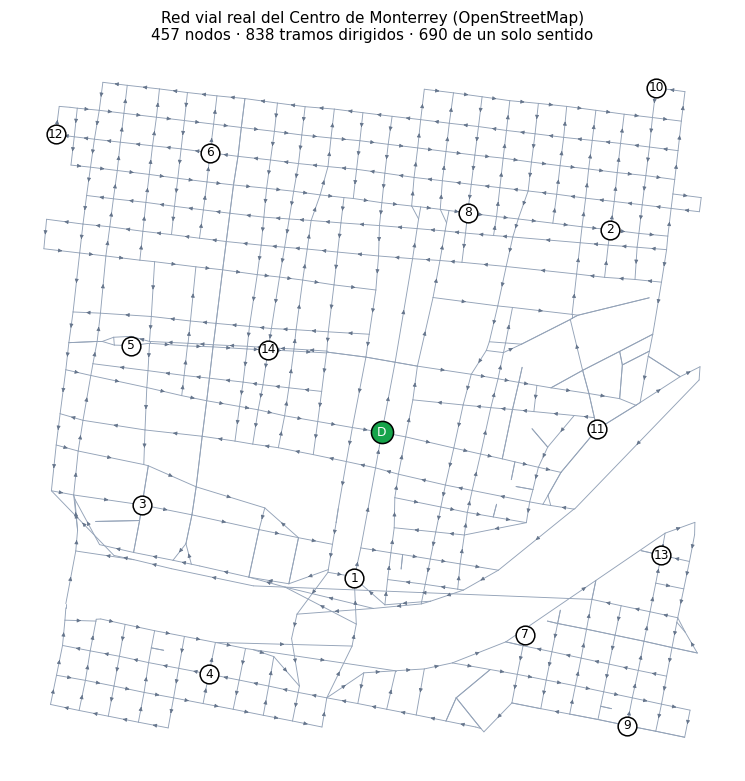

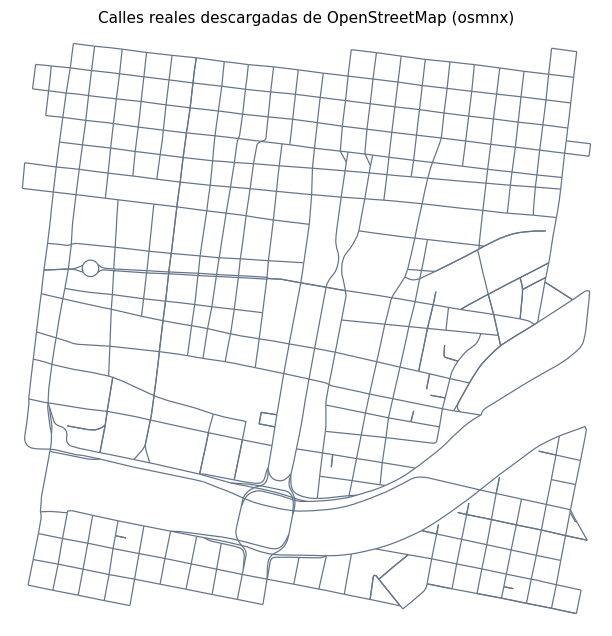

In [6]:
# Mapa de la red vial real con el depósito y las paradas (figura 1)
def dibujar_red(ax, lw=.6):
    for a, b, *_ in E:
        ax.plot(*zip(xy[a], xy[b]), c="#94a3b8", lw=lw, solid_capstyle="round")
    par = {(a, b) for a, b, *_ in E}
    for a, b, *_ in E:                                    # flechas en calles de un solo sentido
        if (b, a) not in par:
            m = (xy[a]+xy[b])/2; d = xy[b]-xy[a]; n = np.linalg.norm(d)
            if n > 0.06: ax.annotate("", xy=m+d/n*.012, xytext=m-d/n*.012, arrowprops=dict(arrowstyle="-|>", color="#64748b", lw=.5, mutation_scale=5))

fig, ax = plt.subplots(figsize=(7.2, 7.2))
dibujar_red(ax)
for k, p in enumerate(PTS):
    ax.scatter(*xy[p], s=210 if k == 0 else 150, c="#16a34a" if k == 0 else "white", ec="k", zorder=4)
    ax.text(*xy[p], "D" if k == 0 else k, ha="center", va="center", fontsize=8, zorder=5, color="white" if k == 0 else "k")
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Red vial real del Centro de Monterrey (OpenStreetMap)\n{N} nodos · {len(E)} tramos dirigidos · {un_sentido} de un solo sentido", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_red_vial.png"); plt.show()

# Mapa real de OpenStreetMap con osmnx (solo si hubo descarga): geometría exacta de cada calle
if G_osm is not None:
    try:
        import osmnx as ox
        fig, ax = ox.plot_graph(G_osm, node_size=0, edge_color="#64748b", edge_linewidth=.8, bgcolor="white", show=False, close=False, figsize=(7, 7))
        ax.set_title("Calles reales descargadas de OpenStreetMap (osmnx)", fontsize=10)
        fig.savefig(f"{OUT}/fig0_osm_real.png", dpi=130); plt.show()
    except Exception as err:
        print("No se pudo dibujar con osmnx:", err)

## 3. Funciones comunes: costo, 2-opt, Held–Karp (óptimo), vecino más cercano

In [7]:
# Utilidades
def costos(M, tours):
    """tours: (P, n-1) con valores 1..n-1 (el depósito 0 es inicio y fin)."""
    z = np.zeros((tours.shape[0], 1), dtype=int)
    f = np.hstack([z, tours, z])
    return M[f[:, :-1], f[:, 1:]].sum(1)

def _pares(m):
    return np.array([(i, j) for i in range(m-1) for j in range(i+1, m)])

def dos_opt(M, tours):
    """2-opt por mejor mejora, en lote. Invierte tramos mientras reduzca el costo (válido para matrices asimétricas)."""
    tours = tours.copy(); m = tours.shape[1]; pr = _pares(m)
    idx = np.tile(np.arange(m), (len(pr), 1))
    for r, (i, j) in enumerate(pr): idx[r, i:j+1] = np.arange(j, i-1, -1)
    f = costos(M, tours)
    while True:
        cand = tours[:, idx]                                   # (P, pares, m)
        fc = costos(M, cand.reshape(-1, m)).reshape(len(tours), -1)
        b = fc.argmin(1); mejora = fc[np.arange(len(tours)), b] < f - 1e-12
        if not mejora.any(): return tours, f
        tours[mejora] = cand[np.arange(len(tours)), b][mejora]
        f = np.where(mejora, fc[np.arange(len(tours)), b], f)

def held_karp(M):
    n = len(M); m = n-1; S_ = 1 << m
    dp = np.full((S_, m), np.inf); par = np.full((S_, m), -1, dtype=int)
    for j in range(m): dp[1 << j, j] = M[0, j+1]
    for S in range(1, S_):
        for j in range(m):
            if not (S >> j) & 1 or not np.isfinite(dp[S, j]): continue
            for k in range(m):
                if (S >> k) & 1: continue
                v = dp[S, j] + M[j+1, k+1]; T = S | (1 << k)
                if v < dp[T, k]: dp[T, k] = v; par[T, k] = j
    full = S_-1; fin = dp[full] + M[1:, 0]; j = int(fin.argmin()); best = fin[j]
    tour = []; S = full
    while j != -1:
        tour.append(j+1); pj = par[S, j]; S ^= (1 << j); j = pj
    return best, np.array(tour[::-1])

def vecino_mas_cercano(M):
    n = len(M); vis = {0}; t = []; cur = 0
    while len(vis) < n:
        c = min((j for j in range(n) if j not in vis), key=lambda j: M[cur, j]); t.append(c); vis.add(c); cur = c
    return costos(M, np.array([t]))[0], np.array(t)

t0 = time.time()
OPT_D, RUTA_OPT_D = held_karp(D); OPT_T, RUTA_OPT_T = held_karp(Tm)
NN_D, RUTA_NN = vecino_mas_cercano(D)
print(f"Óptimo distancia = {OPT_D:.3f} km | óptimo tiempo = {OPT_T:.2f} min | NN = {NN_D:.3f} km ({100*(NN_D/OPT_D-1):.1f}% sobre el óptimo) [{time.time()-t0:.1f}s]")

Óptimo distancia = 14.347 km | óptimo tiempo = 21.50 min | NN = 16.512 km (15.1% sobre el óptimo) [1.8s]


## 4. Algoritmos
**PSO** con *random keys*: cada partícula es un vector real de 14 números; `argsort` da el orden de visita.
`v = w·v + c1·r1·(pbest − x) + c2·r2·(gbest − x)`, `|v| ≤ 1.5`.

**ACO** (Ant System + hormigas elitistas): `p(i→j) ∝ τ^α · (1/d)^β`, evaporación ρ, depósito Q/L, y refuerzo e·Q/L a la mejor ruta global. Feromona **dirigida** (la matriz es asimétrica).

Las variantes `local=True` aplican 2-opt (híbridos).

In [8]:
# PSO y ACO
def pso(M, P=50, w=0.9, c1=2.0, c2=2.0, iters=ITERS, seed=0, vmax=1.5, local=False):
    rng = np.random.default_rng(seed); m = len(M)-1
    x = rng.random((P, m)); v = rng.uniform(-.5, .5, (P, m)); ar = np.arange(P)[:, None]
    def decodificar(x):
        t = np.argsort(x, axis=1) + 1
        if local:
            t, f = dos_opt(M, t); x[ar, t-1] = np.arange(m)/m      # escribir de regreso el orden mejorado
        else: f = costos(M, t)
        return t, f
    t, f = decodificar(x); pb, pf = x.copy(), f.copy()
    g = f.argmin(); gb, gf, gt = x[g].copy(), f[g], t[g].copy(); hist = []
    for _ in range(iters):
        v = np.clip(w*v + c1*rng.random((P, m))*(pb-x) + c2*rng.random((P, m))*(gb-x), -vmax, vmax)
        x = x + v; t, f = decodificar(x)
        mej = f < pf; pb[mej] = x[mej]; pf[mej] = f[mej]
        g = f.argmin()
        if f[g] < gf: gf, gb, gt = f[g], x[g].copy(), t[g].copy()
        hist.append(gf)
    return gt, gf, np.array(hist)

def aco(M, A=30, alpha=0.5, beta=2.0, rho=0.5, iters=ITERS, seed=0, Q=1.0, e=5, local=False):
    rng = np.random.default_rng(seed); n = len(M); eta = 1/(M + np.eye(n))
    tau = np.full((n, n), 1/vecino_mas_cercano(M)[0]); gt, gf = None, np.inf; hist = []
    for _ in range(iters):
        Pm = tau**alpha * eta**beta
        vis = np.zeros((A, n), bool); vis[:, 0] = True; cur = np.zeros(A, int); tours = np.zeros((A, n-1), int)
        for s in range(n-1):
            w = Pm[cur]; w[vis] = 0; p = w/w.sum(1, keepdims=True)
            nxt = np.minimum((p.cumsum(1) < rng.random((A, 1))).sum(1), n-1)
            nxt = np.where(vis[np.arange(A), nxt], (w > 0).argmax(1), nxt)      # protección numérica
            tours[:, s] = nxt; vis[np.arange(A), nxt] = True; cur = nxt
        if local: tours, f = dos_opt(M, tours)
        else: f = costos(M, tours)
        b = f.argmin()
        if f[b] < gf: gf, gt = f[b], tours[b].copy()
        tau *= (1-rho)
        for tr, L in zip(tours, f):
            ruta = np.r_[0, tr, 0]; tau[ruta[:-1], ruta[1:]] += Q/L
        ruta = np.r_[0, gt, 0]; tau[ruta[:-1], ruta[1:]] += e*Q/gf
        tau = np.maximum(tau, 1e-12); hist.append(gf)
    return gt, gf, np.array(hist)

## 5. Experimento: búsqueda en malla (24 configuraciones PSO + 24 ACO) × 15 corridas

In [9]:
# Experimento
def correr(fn, M, opt, cfg, corridas=CORRIDAS, **fijos):
    fs, its, tms, hs, ts = [], [], [], [], []
    for s in range(corridas):
        t0 = time.perf_counter(); t, f, h = fn(M, seed=s, **cfg, **fijos); tms.append((time.perf_counter()-t0)*1000)
        fs.append(f); its.append(int(np.argmax(h <= f + 1e-9)) + 1); hs.append(h); ts.append(t)
    fs = np.array(fs)
    return dict(**cfg, Mejor=fs.min(), Promedio=fs.mean(), Peor=fs.max(), Desv=fs.std(ddof=1),
                Brecha=100*(fs.mean()/opt-1), Optimo=int((fs <= opt+1e-6).sum()), IterMejor=float(np.mean(its)),
                ms=float(np.mean(tms))), fs, np.mean(hs, 0), np.std(hs, 0), ts[int(fs.argmin())]

malla_pso = [dict(P=a, w=b, c1=c, c2=d) for a, b, c, d in itertools.product([20, 50], [.4, .7, .9], [1., 2.], [1., 2.])]
malla_aco = [dict(A=a, alpha=b, beta=c, rho=d) for a, b, c, d in itertools.product([10, 30], [.5, 1., 2.], [2., 5.], [.1, .5])]
t0 = time.time()
R_pso = [correr(pso, D, OPT_D, c) for c in malla_pso]
R_aco = [correr(aco, D, OPT_D, c) for c in malla_aco]
df_pso = pd.DataFrame([r[0] for r in R_pso]); df_aco = pd.DataFrame([r[0] for r in R_aco])
df_pso.index = df_aco.index = range(1, 25)
df_pso.to_csv(f"{OUT}/tabla_pso.csv"); df_aco.to_csv(f"{OUT}/tabla_aco.csv")
print(f"Malla completa en {time.time()-t0:.0f}s")
print(df_pso.round(3).to_string()); print(df_aco.round(3).to_string())

Malla completa en 109s
     P    w   c1   c2   Mejor  Promedio    Peor   Desv  Brecha  Optimo  IterMejor       ms
1   20  0.4  1.0  1.0  17.880    20.236  21.732  1.189  41.050       0     38.200   14.000
2   20  0.4  1.0  2.0  17.205    20.339  25.101  2.308  41.764       0     30.133   13.948
3   20  0.4  2.0  1.0  15.997    17.928  20.399  1.378  24.963       0     61.533   13.973
4   20  0.4  2.0  2.0  14.347    16.986  18.362  1.220  18.395       1     97.600   16.114
5   20  0.7  1.0  1.0  15.838    19.079  21.188  1.509  32.982       0     34.200   13.661
6   20  0.7  1.0  2.0  14.637    17.636  20.745  1.600  22.924       0     67.000   13.937
7   20  0.7  2.0  1.0  14.347    16.219  18.147  1.216  13.050       1    108.800   13.975
8   20  0.7  2.0  2.0  15.296    17.471  20.082  1.372  21.771       0    124.467   15.589
9   20  0.9  1.0  1.0  15.077    16.915  18.906  1.101  17.901       0    151.400   14.481
10  20  0.9  1.0  2.0  14.347    17.575  19.532  1.546  22.502     

In [10]:
# Mejores configuraciones y comparación directa (distancia)
ip, ia = df_pso.Promedio.idxmin()-1, df_aco.Promedio.idxmin()-1
cfg_p, cfg_a = malla_pso[ip], malla_aco[ia]
print("Mejor PSO:", cfg_p, "| Mejor ACO:", cfg_a)
res = {"ACO": R_aco[ia], "PSO": R_pso[ip], "PSO + 2-opt": correr(pso, D, OPT_D, cfg_p, local=True),
       "ACO + 2-opt": correr(aco, D, OPT_D, cfg_a, local=True)}
comp = pd.DataFrame({k: v[0] for k, v in res.items()}).loc[["Mejor", "Promedio", "Peor", "Desv", "Brecha", "Optimo", "IterMejor", "ms"]]
comp.to_csv(f"{OUT}/comparacion_distancia.csv"); print(comp.round(3))

Mejor PSO: {'P': 50, 'w': 0.7, 'c1': 2.0, 'c2': 1.0} | Mejor ACO: {'A': 30, 'alpha': 0.5, 'beta': 2.0, 'rho': 0.5}
               ACO     PSO  PSO + 2-opt  ACO + 2-opt
Mejor       14.347  14.347       14.347       14.347
Promedio    14.365  15.925       14.347       14.347
Peor        14.414  17.212       14.347       14.347
Desv         0.031   0.852        0.000        0.000
Brecha       0.125  10.996        0.000        0.000
Optimo      11.000   2.000       15.000       15.000
IterMejor   63.000  92.267        1.000        1.000
ms         293.239  55.131      606.686     1481.035


In [11]:
# Experimento: minimizar tiempo
res_t = {"ACO": correr(aco, Tm, OPT_T, cfg_a), "PSO": correr(pso, Tm, OPT_T, cfg_p),
         "PSO + 2-opt": correr(pso, Tm, OPT_T, cfg_p, local=True), "ACO + 2-opt": correr(aco, Tm, OPT_T, cfg_a, local=True)}
comp_t = pd.DataFrame({k: v[0] for k, v in res_t.items()}).loc[["Mejor", "Promedio", "Peor", "Desv", "Brecha", "Optimo"]]
comp_t.to_csv(f"{OUT}/comparacion_tiempo.csv"); print(comp_t.round(3))

             ACO     PSO  PSO + 2-opt  ACO + 2-opt
Mejor     21.499  21.499       21.499       21.499
Promedio  21.514  22.818       21.499       21.499
Peor      21.722  24.439       21.499       21.499
Desv       0.058   0.950        0.000        0.000
Brecha     0.069   6.137        0.000        0.000
Optimo    14.000   1.000       15.000       15.000


## 6. Gráficas

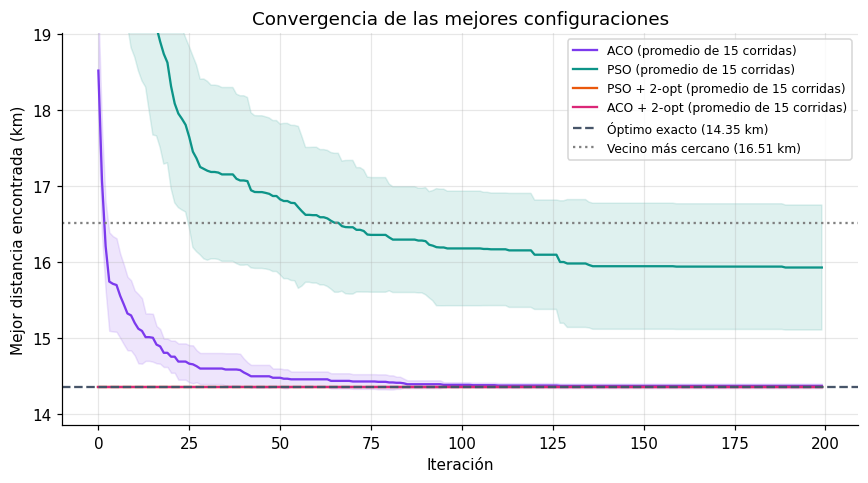

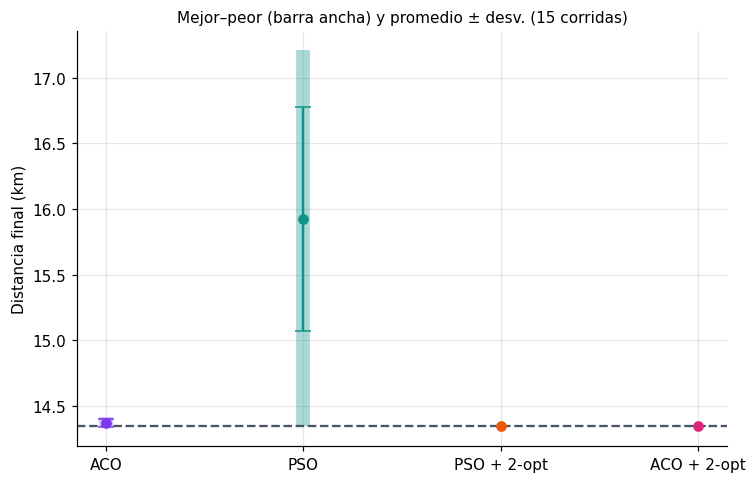

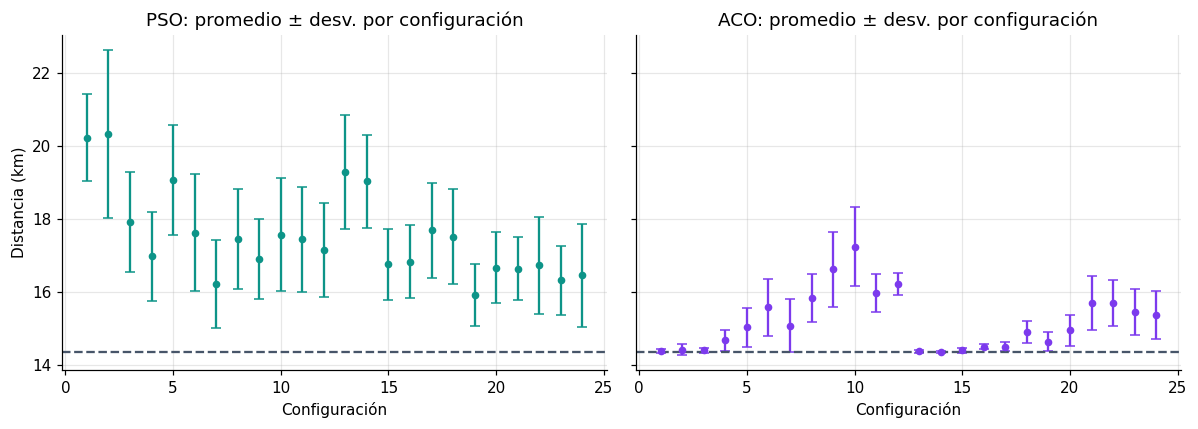

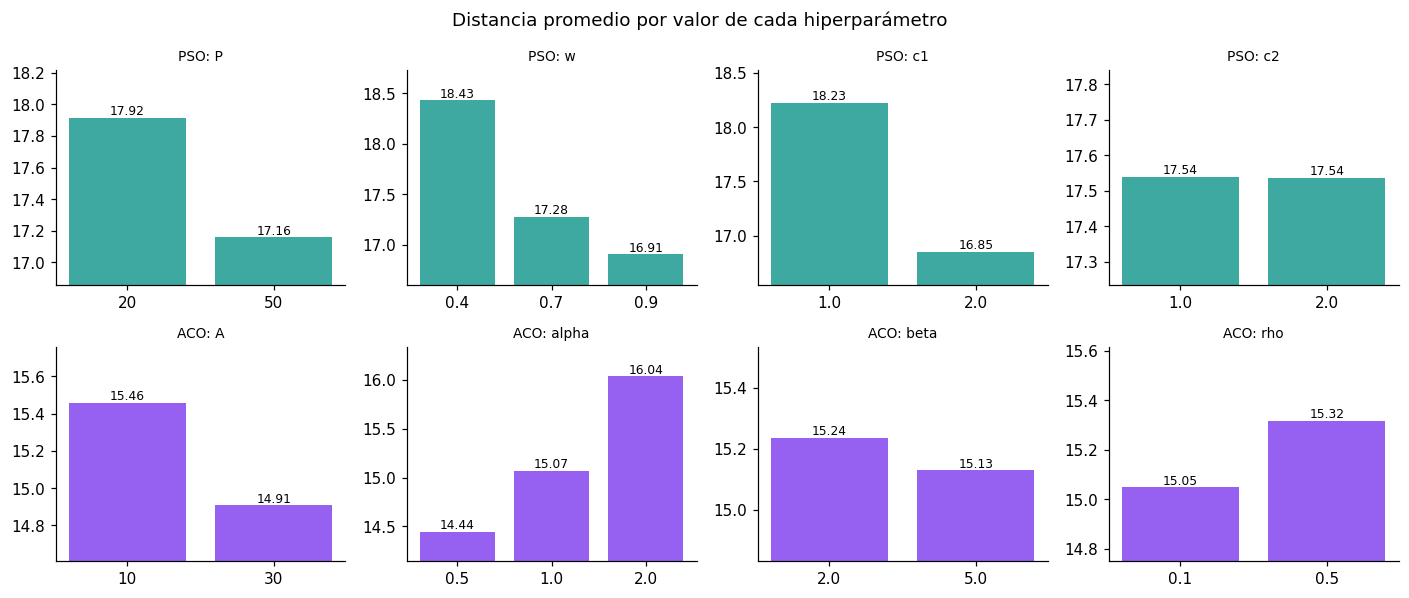

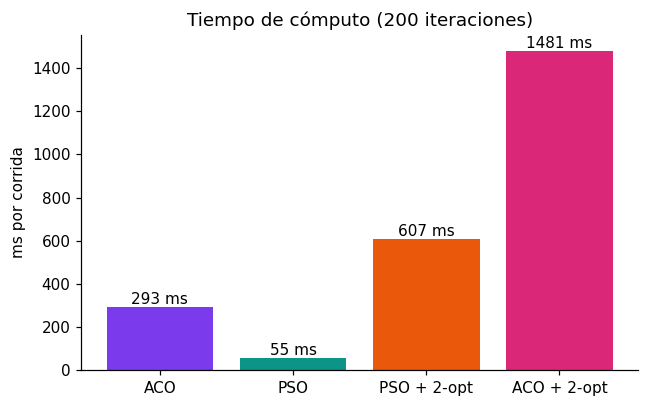

In [12]:
# Gráficas estadísticas
col = {"ACO": C_ACO, "PSO": C_PSO, "PSO + 2-opt": C_HIB, "ACO + 2-opt": "#db2777"}
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, r in res.items():
    h, s = r[2], r[3]; ax.plot(h, color=col[k], label=f"{k} (promedio de {CORRIDAS} corridas)"); ax.fill_between(range(len(h)), h-s, h+s, color=col[k], alpha=.13)
ax.axhline(OPT_D, ls="--", c=C_REF, label=f"Óptimo exacto ({OPT_D:.2f} km)"); ax.axhline(NN_D, ls=":", c="gray", label=f"Vecino más cercano ({NN_D:.2f} km)")
ax.set_xlabel("Iteración"); ax.set_ylabel("Mejor distancia encontrada (km)"); ax.set_title("Convergencia de las mejores configuraciones"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_ylim(OPT_D-.5, NN_D+2.5); fig.tight_layout(); fig.savefig(f"{OUT}/fig2_convergencia.png"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5)); ks = list(res)
for i, k in enumerate(ks):
    f = res[k][1]
    ax.vlines(i, f.min(), f.max(), color=col[k], lw=9, alpha=.35)                       # rango mejor–peor
    ax.errorbar(i, f.mean(), f.std(ddof=1), fmt="o", c=col[k], capsize=5, lw=1.6)       # promedio ± desv.
ax.set_xticks(range(len(ks))); ax.set_xticklabels(ks)
ax.axhline(OPT_D, ls="--", c=C_REF); ax.set_ylabel("Distancia final (km)"); ax.set_title(f"Mejor–peor (barra ancha) y promedio ± desv. ({CORRIDAS} corridas)", fontsize=10); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_rango.png"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, df, c, t in [(axs[0], df_pso, C_PSO, "PSO"), (axs[1], df_aco, C_ACO, "ACO")]:
    ax.errorbar(df.index, df.Promedio, df.Desv, fmt="o", c=c, capsize=3, ms=4); ax.axhline(OPT_D, ls="--", c=C_REF)
    ax.set_title(f"{t}: promedio ± desv. por configuración"); ax.set_xlabel("Configuración"); ax.grid(alpha=.3)
axs[0].set_ylabel("Distancia (km)"); fig.tight_layout(); fig.savefig(f"{OUT}/fig4_configs.png"); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(13, 5.5)); efectos = {}
for r, (df, hp, c, nom) in enumerate([(df_pso, ["P", "w", "c1", "c2"], C_PSO, "PSO"), (df_aco, ["A", "alpha", "beta", "rho"], C_ACO, "ACO")]):
    for q, h in enumerate(hp):
        g = df.groupby(h).Promedio.mean(); efectos[f"{nom}:{h}"] = {str(k): float(v) for k, v in g.items()}
        axs[r, q].bar(g.index.astype(str), g.values, color=c, alpha=.8); axs[r, q].set_title(f"{nom}: {h}", fontsize=9)
        axs[r, q].set_ylim(g.min()-.3, g.max()+.3)
        for i, v in enumerate(g.values): axs[r, q].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Distancia promedio por valor de cada hiperparámetro"); fig.tight_layout(); fig.savefig(f"{OUT}/fig5_hiperparametros.png"); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.8)); ks = list(res)
ax.bar(ks, [res[k][0]["ms"] for k in ks], color=[col[k] for k in ks])
for i, k in enumerate(ks): ax.text(i, res[k][0]["ms"], f"{res[k][0]['ms']:.0f} ms", ha="center", va="bottom")
ax.set_ylabel("ms por corrida"); ax.set_title(f"Tiempo de cómputo ({ITERS} iteraciones)"); fig.tight_layout(); fig.savefig(f"{OUT}/fig6_tiempo.png"); plt.show()

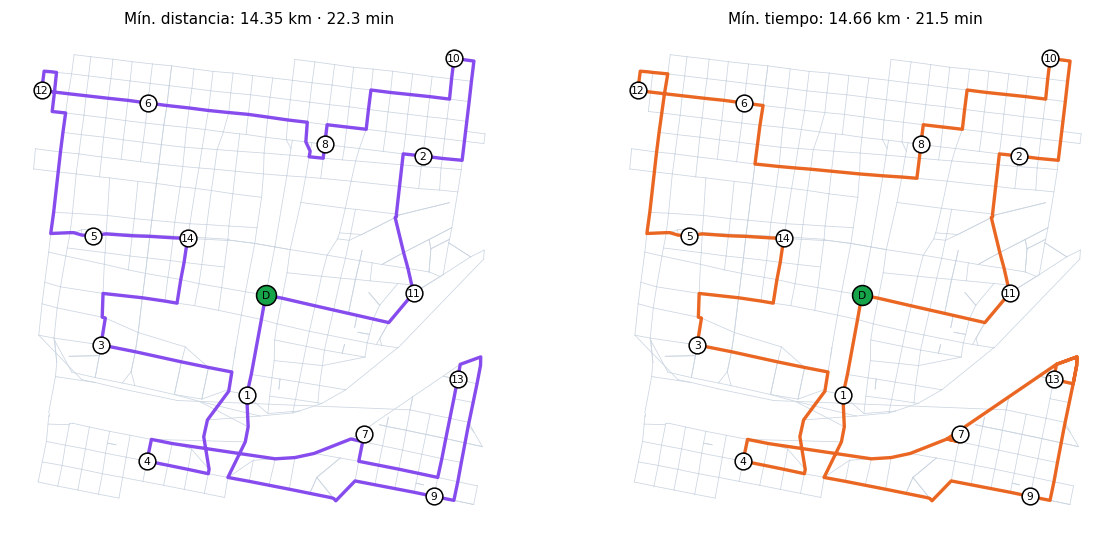

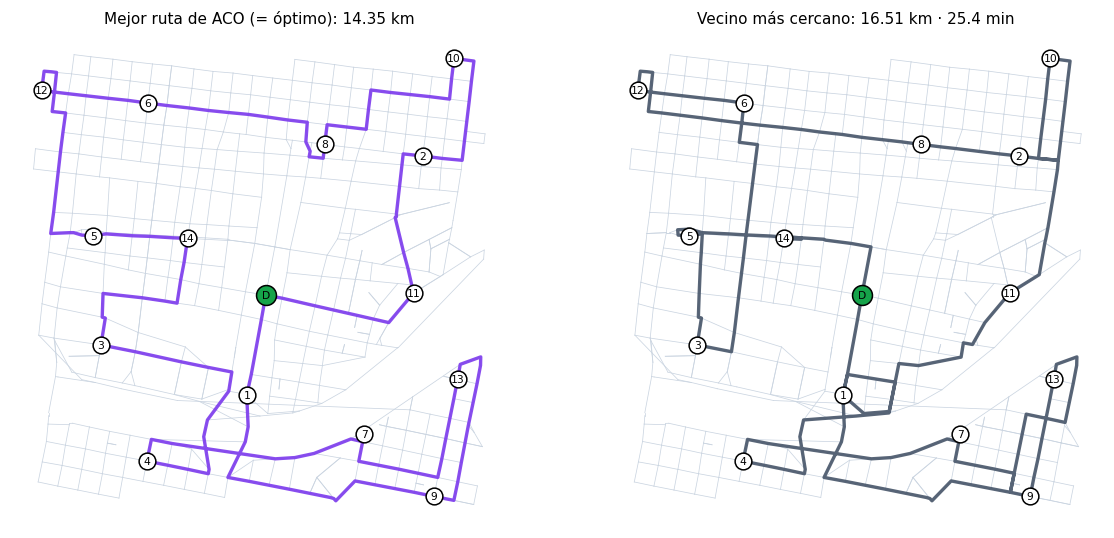

In [13]:
# Mapas de rutas sobre las calles
def camino(pred, a, b):
    p = [PTS[b]]
    while p[-1] != PTS[a]: p.append(int(pred[a, p[-1]]))
    return p[::-1]
def polilinea(orden, pred):
    r = np.r_[0, orden, 0]; nodos = []
    for a, b in zip(r[:-1], r[1:]): nodos += camino(pred, a, b)[:-1]
    return nodos + [PTS[0]]
def dibujar(ax, orden, pred, color, titulo):
    for a, b, *_ in E: ax.plot(*zip(xy[a], xy[b]), c="#cbd5e1", lw=.5)
    pl = polilinea(orden, pred); ax.plot(xy[pl, 0], xy[pl, 1], c=color, lw=2.2, alpha=.9)
    for k, p in enumerate(PTS):
        ax.scatter(*xy[p], s=170 if k == 0 else 120, c="#16a34a" if k == 0 else "white", ec="k", zorder=4)
        ax.text(*xy[p], "D" if k == 0 else k, ha="center", va="center", fontsize=7, zorder=5)
    ax.set_title(titulo, fontsize=10); ax.set_aspect("equal"); ax.axis("off")
# km y minutos reales de una ruta siguiendo las calles del camino más corto elegido (por distancia o por tiempo)
ARISTA = {}
for a, b, l, s in E:
    if (a, b) not in ARISTA or l < ARISTA[(a, b)][0]: ARISTA[(a, b)] = (l, s)
def recorrido(orden, pred):
    nodos = polilinea(orden, pred); pares = list(zip(nodos[:-1], nodos[1:]))
    km = sum(ARISTA[p][0] for p in pares); mn = sum(ARISTA[p][0]/ARISTA[p][1]*60 for p in pares)
    return km, mn
R_DIST = recorrido(RUTA_OPT_D, PL); R_TIEMPO = recorrido(RUTA_OPT_T, PT)
R_ACO  = recorrido(res["ACO"][4], PL); R_NN = recorrido(RUTA_NN, PL)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
dibujar(axs[0], RUTA_OPT_D, PL, C_ACO, f"Mín. distancia: {R_DIST[0]:.2f} km · {R_DIST[1]:.1f} min")
dibujar(axs[1], RUTA_OPT_T, PT, C_HIB, f"Mín. tiempo: {R_TIEMPO[0]:.2f} km · {R_TIEMPO[1]:.1f} min")
fig.tight_layout(); fig.savefig(f"{OUT}/fig7_rutas_dist_tiempo.png"); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
dibujar(axs[0], res["ACO"][4], PL, C_ACO, f"Mejor ruta de ACO (= óptimo): {R_ACO[0]:.2f} km" if abs(res["ACO"][0]["Mejor"]-OPT_D) < 1e-6 else f"Mejor ruta de ACO: {R_ACO[0]:.2f} km")
dibujar(axs[1], RUTA_NN, PL, C_REF, f"Vecino más cercano: {R_NN[0]:.2f} km · {R_NN[1]:.1f} min")
fig.tight_layout(); fig.savefig(f"{OUT}/fig8_rutas_aco_nn.png"); plt.show()

In [14]:
# Exportar resultados para la página web y para el reporte
def lim(v): return [round(float(a), 4) for a in v[::4]]
web = dict(
  graph=dict(nodes=np.round(xy, 3).tolist(), edges=[[a, b, round(l, 4), s] for a, b, l, s in E], names=nombres, stops=PTS),
  ref=dict(opt_d=OPT_D, opt_t=OPT_T, nn_d=NN_D, ruta_opt_d=RUTA_OPT_D.tolist(), ruta_opt_t=RUTA_OPT_T.tolist(), ruta_nn=RUTA_NN.tolist()),
  mejores=dict(pso=cfg_p, aco=cfg_a),
  comparacion={k: {m: float(v) for m, v in comp[k].items()} for k in comp},
  comparacion_t={k: {m: float(v) for m, v in comp_t[k].items()} for k in comp_t},
  conv={k: lim(r[2]) for k, r in res.items()},
  tabla_pso=df_pso.round(3).reset_index().to_dict("records"), tabla_aco=df_aco.round(3).reset_index().to_dict("records"),
  efectos=efectos,
  extra=dict(asimetria_max=float(asim), un_sentido=int(un_sentido), mejor_ruta_aco=[int(i) for i in res["ACO"][4]],
             ruta_dist=[float(x) for x in R_DIST], ruta_tiempo=[float(x) for x in R_TIEMPO],
             ruta_nn=[float(x) for x in R_NN], ruta_aco=[float(x) for x in R_ACO], fuente=fuente))
json.dump(web, open(f"{OUT}/resultados.json", "w"))
print("Listo. Archivos en", OUT, "->", sorted(os.listdir(OUT)))

Listo. Archivos en resultados -> ['comparacion_distancia.csv', 'comparacion_tiempo.csv', 'fig0_osm_real.png', 'fig1_red_vial.png', 'fig2_convergencia.png', 'fig3_rango.png', 'fig4_configs.png', 'fig5_hiperparametros.png', 'fig6_tiempo.png', 'fig7_rutas_dist_tiempo.png', 'fig8_rutas_aco_nn.png', 'puntos.csv', 'resultados.json', 'tabla_aco.csv', 'tabla_pso.csv']


In [15]:
# (Colab) descargar todos los resultados en un .zip
import shutil
shutil.make_archive("resultados_rutabio", "zip", OUT)
try:
    from google.colab import files
    files.download("resultados_rutabio.zip")
except ImportError:
    print("Fuera de Colab: el archivo resultados_rutabio.zip quedó en la carpeta actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>